# 703. Kth Largest Element in a Stream
**Difficulty:** 🟢 Easy · **Topic:** Heap · **Pattern:** [Top K](README.md) · **LeetCode:** https://leetcode.com/problems/kth-largest-element-in-a-stream/

## 💡 Concepts

**Core concept(s):** **Top K with a size-k min-heap** — keep only the `k` largest values seen so far; the smallest of them is the answer.

**Why it applies here:**
- Values arrive one at a time (a *stream*), and after every arrival we must report the k-th largest.
- Only the `k` largest values can ever be the answer again. Everything below them is dead weight.
- A min-heap of those `k` values keeps the k-th largest at index `0`, ready to read in **O(1)**.

**Key intuition:**
- Think of a club with `k` seats. The min-heap root is the weakest person seated.
- A newcomer sits down; if there are now `k + 1` people, the weakest one leaves.
- Whoever is weakest *after* that is exactly the k-th largest.

---

### 📚 What is a Heap / Priority Queue?
- A **priority queue** is a bag of items where you can always take out the "most important" one next — here, the smallest.
- A **binary heap** is how it is built: a complete binary tree stored in a plain list, where every parent is `<=` its children (a **min-heap**).
- So the smallest item is always at index `0`; you can *peek* at it in **O(1)**.
- `push` adds at the end and bubbles the item up; `pop` removes the root, moves the last item to the top and sifts it down. Both are **O(log size)** because the tree is only `log size` levels tall.
- `heapify(list)` turns any list into a heap in **O(n)**.
- **In Python:** the `heapq` module works on a plain `list`: `heappush`, `heappop`, `heapify`, `heap[0]` to peek. It is a **min-heap only** — for a max-heap, push negated keys (`-x`).
- Tuples compare item by item, so `heappush(h, (priority, payload))` orders by `priority` first.

### 📚 What is the Top-K (size-k heap) technique?
- To keep the **k largest** values seen so far, keep them in a **min-heap capped at size k**.
- The root is the *smallest of the k largest* — the **k-th largest** overall. It is the "bouncer at the door".
- Each new value is pushed; if the heap grows to `k + 1`, pop the root. The value that leaves is the one that can no longer be in the top k.
- Each step is **O(log k)**, so `n` values cost **O(n log k)** time and only **O(k)** memory, instead of sorting all `n`.
- The direction is the counter-intuitive part: **k largest → min-heap**, **k smallest → max-heap** (the root is always the one to evict next).

### 📚 What is Sorting / Binary Search (`bisect`)?
- **Sorting** puts values in order; Python's `sorted` / `list.sort` (Timsort) is **O(n log n)**.
- **Binary search** finds a position in a *sorted* list by halving the range each step: **O(log n)**.
- `bisect.insort(a, x)` finds the slot with binary search (O(log n)) but then **shifts** every later element one place right to make room: **O(n)** per insert.
- **In Python:** `sorted(...)`, `bisect.insort`, `bisect.bisect_left`.

---

**Prerequisite knowledge:**
- Python classes (`__init__`, methods, `self`).
- How a design problem is tested: a list of operation names plus a list of arguments.

## 📝 Problem

Design a class that tracks the **k-th largest** score in a stream of test scores.

- `KthLargest(k, nums)` — start with the integer `k` and the scores already seen, `nums`.
- `add(val)` — add a new score `val` to the stream, then **return the k-th largest score** so far.

"k-th largest" means in sorted order, not distinct: in `[8, 5, 5, 4]` the 2nd largest is `5` and the 3rd largest is also `5`.

**Example 1**
```
["KthLargest", "add", "add", "add", "add", "add"]
[[3, [4, 5, 8, 2]], [3], [5], [10], [9], [4]]
-> [null, 4, 5, 5, 8, 8]

k = 3, start with [4, 5, 8, 2]
add(3)  -> stream [2,3,4,5,8]          3rd largest = 4
add(5)  -> stream [2,3,4,5,5,8]        3rd largest = 5
add(10) -> stream [2,3,4,5,5,8,10]     3rd largest = 5
add(9)  -> stream [2,3,4,5,5,8,9,10]   3rd largest = 8
add(4)  -> stream [...,4,5,5,8,9,10]   3rd largest = 8
```

**Example 2**
```
["KthLargest", "add", "add", "add", "add"]
[[4, [7, 7, 7, 7, 8, 3]], [2], [10], [9], [9]]
-> [null, 7, 7, 7, 8]
```

**Constraints:** `0 <= nums.length <= 10⁴`, `1 <= k <= nums.length + 1`, `-10⁴ <= nums[i], val <= 10⁴`, at most `10⁴` calls to `add`. When `add` is called there are always at least `k` values in the stream.

> Three approaches: re-sort the whole stream on every `add`, keep the stream sorted with `bisect.insort`, then the size-k min-heap (the pattern template).

In [1]:
import bisect
import heapq
import random
from typing import List


def run_ops(cls, ops, args):
    """Replay a LeetCode-style design test: ops[i] is a method name, args[i] its arguments.
    The first op is the constructor; its output is None (LeetCode prints `null`)."""
    obj = cls(*args[0])
    out = [None]
    for op, a in zip(ops[1:], args[1:]):
        out.append(getattr(obj, op)(*a))
    return out

### Approach 1 — Brute Force: re-sort the whole stream on every `add`

**Idea:**
1. Keep every score ever seen in a plain list, in arrival order.
2. On `add(val)`, append `val`, sort a copy of the whole list, and read the element `k` from the end.

**Time complexity:** `O(n log n)` per `add` — the whole stream of `n` values is sorted again each time (the list is kept in arrival order, so the sort cannot reuse earlier work).

**Space complexity:** `O(n)` — every value is stored, plus the sorted copy.

In [2]:
class KthLargestBrute:
    def __init__(self, k: int, nums: List[int]):
        self.k = k
        self.stream = list(nums)               # every score ever seen, in arrival order

    def add(self, val: int) -> int:
        self.stream.append(val)
        return sorted(self.stream)[-self.k]    # full sort every call: O(n log n)

### Approach 2 — Better: keep the stream sorted with `bisect.insort`

**Idea:**
1. Sort `nums` once in the constructor.
2. On `add(val)`, `bisect.insort` drops `val` into its sorted slot, so the list never needs a full re-sort.
3. The k-th largest is simply `self.sorted[-k]`.

**Time complexity:** `O(n log n)` once for the constructor; then `O(n)` per `add` — binary search finds the slot in `O(log n)`, but inserting shifts every later element one place right.

**Space complexity:** `O(n)` — every value is still stored.

In [3]:
class KthLargestSorted:
    def __init__(self, k: int, nums: List[int]):
        self.k = k
        self.sorted = sorted(nums)             # one O(n log n) sort up front

    def add(self, val: int) -> int:
        bisect.insort(self.sorted, val)        # O(log n) search + O(n) shift
        return self.sorted[-self.k]            # k-th from the end = k-th largest

### Approach 3 — Size-k min-heap (optimal · pattern template)

**Idea:** the [Top K](README.md) template.
1. Keep a **min-heap of at most `k` values** — the `k` largest seen so far.
2. To add a value: push it; if the heap now holds `k + 1` values, pop the root (the smallest). It can never be among the top `k` again.
3. The root `heap[0]` is the smallest of the top `k` = **the k-th largest**.
4. The constructor just runs the same "add" step for each value in `nums`.

**Time complexity:** `O(n log k)` for the constructor, `O(log k)` per `add` — the heap never holds more than `k + 1` values.

**Space complexity:** `O(k)` — values below the top `k` are thrown away for good.

> Why a **min**-heap for the **largest** values: the item we need to evict next (the weakest of the top k) must sit at the root, and only the root is cheap to remove.

In [4]:
class KthLargest:
    def __init__(self, k: int, nums: List[int]):
        self.k = k
        self.heap = []                         # min-heap of the k largest values seen
        for x in nums:
            self.add(x)                        # same push-then-trim step as a streamed value

    def add(self, val: int) -> int:
        heapq.heappush(self.heap, val)
        if len(self.heap) > self.k:            # one too many: the root is no longer top-k
            heapq.heappop(self.heap)
        return self.heap[0]                    # smallest of the top k = k-th largest

In [5]:
# Correctness check
tests = [
    (["KthLargest", "add", "add", "add", "add", "add"],
     [[3, [4, 5, 8, 2]], [3], [5], [10], [9], [4]],
     [None, 4, 5, 5, 8, 8]),                                   # LeetCode example 1
    (["KthLargest", "add", "add", "add", "add"],
     [[4, [7, 7, 7, 7, 8, 3]], [2], [10], [9], [9]],
     [None, 7, 7, 7, 8]),                                      # LeetCode example 2: duplicates count
    (["KthLargest", "add", "add", "add"],
     [[1, []], [-3], [-2], [-4]],
     [None, -3, -2, -2]),                                      # empty start, k = 1, negatives
    (["KthLargest", "add", "add"],
     [[2, [0]], [-1], [1]],
     [None, -1, 0]),                                           # nums has k - 1 values: first add fills the heap
]
for ops, args, exp in tests:
    results = [run_ops(c, ops, args) for c in (KthLargestBrute, KthLargestSorted, KthLargest)]
    print(f"k={args[0][0]}, nums={args[0][1]}, adds={[a[0] for a in args[1:]]} -> {results[2]}")
    assert results[0] == results[1] == results[2] == exp, (ops, args, results)

# Randomised cross-check: all three classes must agree on random streams
rng = random.Random(703)
for _ in range(300):
    nums = [rng.randint(-20, 20) for _ in range(rng.randint(0, 15))]
    k = rng.randint(1, len(nums) + 1)
    adds = [rng.randint(-20, 20) for _ in range(rng.randint(1, 15))]
    ops = ["KthLargest"] + ["add"] * len(adds)
    args = [[k, nums]] + [[v] for v in adds]
    assert run_ops(KthLargestBrute, ops, args) == run_ops(KthLargestSorted, ops, args) == run_ops(KthLargest, ops, args)
print("300 random streams: all three approaches agree")

print("\nAll tests passed")

k=3, nums=[4, 5, 8, 2], adds=[3, 5, 10, 9, 4] -> [None, 4, 5, 5, 8, 8]
k=4, nums=[7, 7, 7, 7, 8, 3], adds=[2, 10, 9, 9] -> [None, 7, 7, 7, 8]
k=1, nums=[], adds=[-3, -2, -4] -> [None, -3, -2, -2]
k=2, nums=[0], adds=[-1, 1] -> [None, -1, 0]
300 random streams: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | a bit over **2×** (≈ 2.1–2.2×) |
| `O(n²)`       | ≈ **4×** |

Each run builds the object with `n` random starting values, then makes `n` more `add` calls, with `k = n // 2` (a large `k` is the heap's worst case). Totals:
- **Brute:** `n` adds × an `O(n log n)` re-sort → `O(n² log n)`, expect a bit over **4×**.
- **Sorted + insort:** `n` adds × an `O(n)` shift → `O(n²)`. The shift is one fast C `memmove`, so at small `n` the per-call overhead hides it and the ratio starts near **2×**; it climbs toward **4×** as `n` grows and the shifting starts to dominate. It is still far faster than the brute force in absolute time.
- **Heap:** `O(n log k)` total, expect ≈ **2×**.


brute re-sort O(n^2 log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |      11.54 |           n/a
     1000 |      50.90 |         4.41x


     2000 |     214.75 |         4.22x


     4000 |    1057.96 |         4.93x

sorted+insort O(n^2) shift
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.08 |           n/a
     1000 |       0.22 |         2.79x
     2000 |       0.59 |         2.72x
     4000 |       1.66 |         2.82x

min-heap O(n log k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.10 |           n/a
     1000 |       0.22 |         2.23x
     2000 |       0.48 |         2.16x
     4000 |       1.02 |         2.10x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


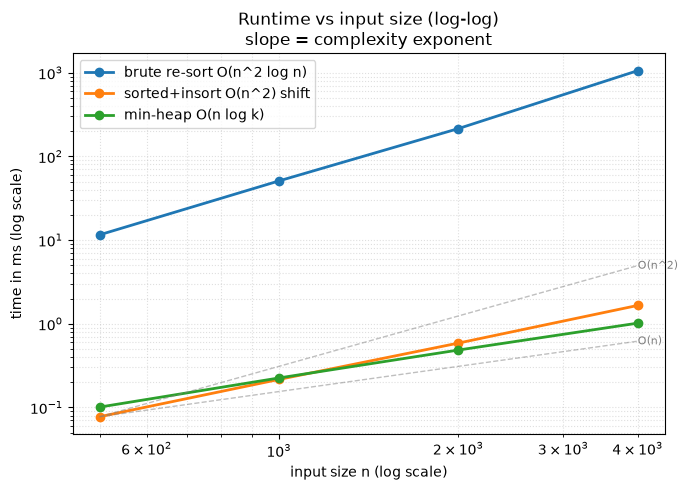

{'brute re-sort O(n^2 log n)': [11.544209090061486,
  50.89779198169708,
  214.75216699764132,
  1057.9598750919104],
 'sorted+insort O(n^2) shift': [0.07737497799098492,
  0.2159159630537033,
  0.5870410241186619,
  1.655207946896553],
 'min-heap O(n log k)': [0.10087492410093546,
  0.22491696290671825,
  0.4848330281674862,
  1.0165829444304109]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark


def make_worst_case(n):
    rng = random.Random(n)
    nums = [rng.randint(-10**4, 10**4) for _ in range(n)]   # random order: no free sorted runs
    adds = [rng.randint(-10**4, 10**4) for _ in range(n)]
    return (n // 2, nums, adds)                             # large k: the heap's worst case

def stream_runner(cls):
    def run(k, nums, adds):
        obj = cls(k, nums)
        for v in adds:
            obj.add(v)
    return run

solutions = {
    "brute re-sort O(n^2 log n)": stream_runner(KthLargestBrute),
    "sorted+insort O(n^2) shift": stream_runner(KthLargestSorted),
    "min-heap O(n log k)": stream_runner(KthLargest),
}
sizes = [500, 1000, 2000, 4000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Top K](README.md) — the textbook case: a min-heap capped at `k` holds the k largest values of the stream, and its root is the answer after every `add`.
- **k largest → min-heap; k smallest → max-heap.** The root must be the value you evict next.
- **Push, then trim:** `heappush`, then `heappop` if `len(heap) > k`. Running the constructor's values through the same `add` keeps one code path.
- **Streams favour heaps over sorting:** a heap pays `O(log k)` per arrival; re-sorting or sorted inserts pay for the whole history every time.
- **Signal:** "k-th largest / smallest", "top k", "as values arrive", "after each insertion", "design a class that returns ... after each add".
- **Related problems:** Kth Largest Element in an Array, K Closest Points to Origin, Top K Frequent Elements, Last Stone Weight, Find Median from Data Stream.
- **Common pitfalls:**
  1. Using a max-heap of every value — correct, but `O(n)` memory and you must pop `k - 1` items per query.
  2. Starting with fewer than `k` values (e.g. `nums = []`): never trim below `k`, and only read `heap[0]` after `add` (the problem guarantees `k` values by then).
  3. Treating "k-th largest" as "k-th distinct" — duplicates count (Example 2).